In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
project_root = Path.cwd()

if not (project_root / "outputs").exists():
    project_root = project_root.parent

csv_path = project_root / "outputs" / "combined_baseline_results.csv"

results = pd.read_csv(csv_path)

print(results)

                       model               partition  n_samples  accuracy  \
0    Majority-class baseline  development_validation       3516  0.135950   
1    Majority-class baseline                ood_test       6231  0.091318   
2  PCA + Random Forest (RGB)  development_validation       3516  0.708476   
3  PCA + Random Forest (RGB)                ood_test       6231  0.448564   

   macro_f1  
0  0.023936  
1  0.016735  
2  0.691049  
3  0.436451  


In [5]:
rf_results = results[
    results["model"] == "PCA + Random Forest (RGB)"
]

print(rf_results)

                       model               partition  n_samples  accuracy  \
2  PCA + Random Forest (RGB)  development_validation       3516  0.708476   
3  PCA + Random Forest (RGB)                ood_test       6231  0.448564   

   macro_f1  
2  0.691049  
3  0.436451  


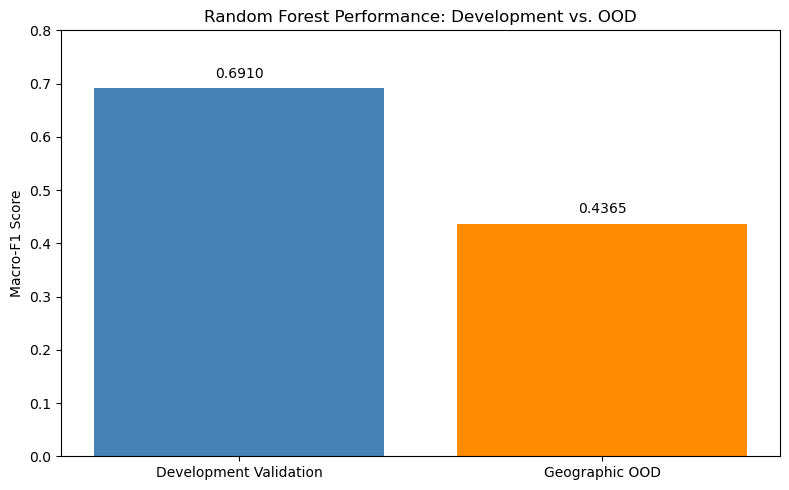

In [6]:
labels = ["Development Validation", "Geographic OOD"]
scores = rf_results.set_index("partition").loc[
    ["development_validation", "ood_test"], "macro_f1"
].values

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, scores, color=["steelblue", "darkorange"])

plt.title("Random Forest Performance: Development vs. OOD")
plt.ylabel("Macro-F1 Score")
plt.ylim(0, 0.8)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.4f}",
        ha="center"
    )

plt.tight_layout()

output_path = project_root / "outputs" / "baseline_f1_comparison.png"
plt.savefig(output_path, dpi=300)
plt.show()

In [7]:
development_f1 = scores[0]
ood_f1 = scores[1]

f1_drop = development_f1 - ood_f1

print(f"Development Macro-F1: {development_f1:.4f}")
print(f"OOD Macro-F1: {ood_f1:.4f}")
print(f"Macro-F1 Drop: {f1_drop:.4f}")

Development Macro-F1: 0.6910
OOD Macro-F1: 0.4365
Macro-F1 Drop: 0.2546


Preliminary Findings

The PCA + Random Forest baseline achieved a Macro-F1 score of 0.6910 on the development validation set and 0.4365 on the geographic OOD test set, representing a decrease of approximately 0.2546 points.

These results suggest reduced generalization performance on geographically different satellite images. However, the geographic partition requires further and more validation, so the findings remain preliminary.